In [7]:

import numpy as np
import matplotlib.pyplot as plt
from specml.data.spectroscopic_data import SpectroscopicData
import specml.processing.masking as masking
import logging
import os

# Configure logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Wavenumber range of interest - let's take only fingerprint region: 1000 to 1800 cm^-1 
lower_wavenumber = 1000
upper_wavenumber = 1800

# Set preprocessing flags
apply_baseline_correction = False 
apply_deriv = False  
area_threshold = 2.0

import specml.processing.preprocessing as preprocessing

def preprocess_sample(spec_data, denoising_method='none'):
    """
    Preprocesses a SpectroscopicData sample.
    """
    # Keep the wavenumber range of interest
    spec_data.keep_range(3550, 950)
    # Remove CO2 and wax regions
    spec_data.remove_co2()
    spec_data.remove_wax()

    area = spec_data.calculate_area(1600,1700)
    tissue_mask = masking.create_mask_from_area(area=area, threshold=area_threshold)
    spec_data.data = masking.apply_mask(spec_data.data, tissue_mask)
    spec_data.mask = masking.rebuild_tissue_mask(spec_data, tissue_mask)

    # Denoising (optional)
    if denoising_method == 'pca':
        spec_data.data = preprocessing.pca_denoising(spec_data.data, n_components=10)
    elif denoising_method == 'mnf':
        spec_data.data = preprocessing.mnf_denoising(spec_data.data, n_components=10)
    elif denoising_method == 'golay':
        # Apply Savitzky-Golay smoothing
        spec_data.data, new_wavenumbers = preprocessing.apply_savitzky_golay(
            spec_data.data,
            wavenumbers=spec_data.wavenumbers,
            window_length=11,
            polyorder=2,
            deriv=0
        )
        spec_data.wavenumbers = new_wavenumbers
    else:
        # No denoising applied
        pass

    # Baseline correction
    from specml.processing.preprocessing import adjust_spectra_min_to_zero
    spec_data.data = adjust_spectra_min_to_zero(spec_data.data)

    # Normalize the spectra
    spec_data.normalize(method='vector')

    # Smoothing (if applicable)
    if apply_deriv:
        spec_data.apply_derivative(window_length=23, polyorder=3, deriv=2)

    return spec_data


In [8]:
import matplotlib.pyplot as plt

# Load your spectral data
spec_data = SpectroscopicData(file_path=f'E:/Lung_Data_8cm/2F-2501-01/1F-2501-01_top/1f-2501-01_top.dmt')

# Create copies of the data for each denoising method
spec_data_no_denoise = spec_data.from_existing()
spec_data_golay = spec_data.from_existing()
spec_data_pca = spec_data.from_existing()
spec_data_mnf = spec_data.from_existing()

# Preprocess each dataset with different denoising methods
spec_data_no_denoise = preprocess_sample(spec_data_no_denoise, denoising_method=None)
spec_data_golay = preprocess_sample(spec_data_golay, denoising_method='golay')
spec_data_pca = preprocess_sample(spec_data_pca, denoising_method='pca')
spec_data_mnf = preprocess_sample(spec_data_mnf, denoising_method='mnf')


INFO:specml.data.loaders:Data loaded from E:/Lung_Data_8cm/2F-2501-01/1F-2501-01_top/1f-2501-01_top.dmt with shape (512, 1792, 754)
INFO:specml.data.spectroscopic_data:Data flattened and mask applied. Shape of processed data: (917504, 754)
INFO:specml.data.spectroscopic_data:{'filename': 'E:/Lung_Data_8cm/2F-2501-01/1F-2501-01_top/1f-2501-01_top.dmt', 'xpixels': 1792, 'ypixels': 512, 'xtiles': 14, 'ytiles': 4, 'numpts': 754, 'fpasize': 128, 'original_shape': (512, 1792, 754)}
INFO:specml.data.spectroscopic_data:Kept wavenumber range from 3550 to 950
INFO:specml.data.spectroscopic_data:Removed wavenumber range from 2250 to 2450
INFO:specml.data.spectroscopic_data:Removed wavenumber range from 1350 to 1490
INFO:specml.data.spectroscopic_data:Removed wavenumber range from 2300 to 2400
INFO:specml.data.spectroscopic_data:Removed wavenumber range from 2700 to 3000
INFO:specml.data.spectroscopic_data:Kept wavenumber range from 3550 to 950
INFO:specml.data.spectroscopic_data:Removed wavenumbe

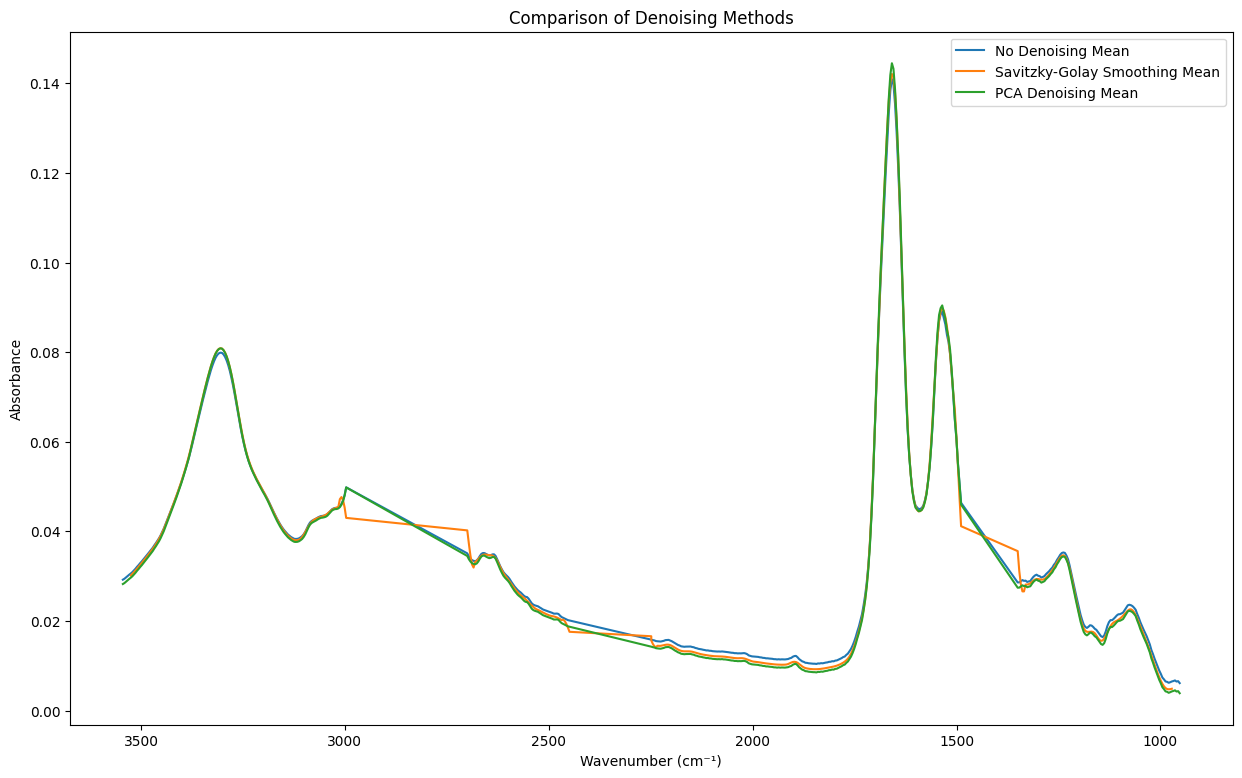

In [11]:
# Prepare the list of datasets and labels
spec_data_list = [
    (spec_data_no_denoise, 'No Denoising'),
    (spec_data_golay, 'Savitzky-Golay Smoothing'),
    (spec_data_pca, 'PCA Denoising'),
    # (spec_data_mnf, 'MNF Denoising')
]


# Initialize the plot
plt.figure(figsize=(15, 9))

# Define confidence level
confidence_level = 0.90
from scipy import stats
for data_obj, label in spec_data_list:
    # Flatten data
    data = data_obj.flatten()
    wavenumbers = data_obj.wavenumbers

    # Ensure at least two spectra are available
    if data.shape[0] < 2:
        raise ValueError("At least two spectra are required to calculate confidence intervals.")

    # Calculate mean and standard deviation
    mean_spectrum = np.mean(data, axis=0)
    std_spectrum = np.std(data, axis=0, ddof=1)

    # Calculate the z-score for the desired confidence level
    z_score = stats.norm.ppf(0.5 + confidence_level / 2)

    # Calculate confidence interval using standard deviation
    h = std_spectrum * z_score

    # Plot mean spectrum
    plt.plot(wavenumbers, mean_spectrum, label=f'{label} Mean')

    # # Plot confidence interval
    # plt.fill_between(
    #     wavenumbers,
    #     mean_spectrum - h,
    #     mean_spectrum + h,
    #     alpha=0.2,
    #     label=f'{label} {int(confidence_level * 100)}% CI'
    # )

# Customize and show the plot
plt.xlabel('Wavenumber (cm⁻¹)')
plt.ylabel('Absorbance')
plt.title('Comparison of Denoising Methods')
plt.legend()
plt.gca().invert_xaxis()  # If wavenumbers are in descending order
plt.show()